**Nombre:** Jesús Antonio Villarraga Palomino
**Fecha:** 21 de octubre de 2025

# Modelamiento predictivo de la interacción en YouTube

En el análisis exploratorio se identificaron diferencias en el alcance y la interacción de los videos según su categoría, canal y características de publicación.

En este cuadernillo pretende un modelo de clasificación para identificar videos con alta interacción, definida a partir de la tasa de likes.
El propósito es reconocer características que puedan orientar la creación de contenidos y apoyar decisiones de negocio.


## 3. Preparación de datos

Se utilizará el conjunto de datos consolidado en el análisis exploratorio, donde se eliminaron los registros exactamente duplicados y se incorporaron los nombres de las categorías.

Para el modelamiento se conservará un registro por video, tomando el de mayor número de visualizaciones observadas. Posteriormente, se calculará la tasa de likes y se definirá como **alta interacción** a los videos que superen el percentil 75 de esta tasa.


In [31]:
import pandas as pd
import shap
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.model_selection import learning_curve

In [2]:
df = pd.read_csv('../data/youtube_consolidado.csv')
df.head()

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,category_name
0,2kyS6SvSYSE,2017-11-14 00:00:00+00:00,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13 17:13:01+00:00,SHANtell martin,748374,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...,People & Blogs
1,1ZAPwfrtAFY,2017-11-14 00:00:00+00:00,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,2017-11-13 07:30:00+00:00,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg,False,False,False,"One year after the presidential election, John...",Entertainment
2,5qpjK5DgCt4,2017-11-14 00:00:00+00:00,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12 19:05:24+00:00,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146033,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...,Comedy
3,puqaWrEC7tY,2017-11-14 00:00:00+00:00,Nickelback Lyrics: Real or Fake?,Good Mythical Morning,24,2017-11-13 11:00:04+00:00,"rhett and link|""gmm""|""good mythical morning""|""...",343168,10172,666,2146,https://i.ytimg.com/vi/puqaWrEC7tY/default.jpg,False,False,False,Today we find out if Link is a Nickelback amat...,Entertainment
4,d380meD0W0M,2017-11-14 00:00:00+00:00,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12 18:01:41+00:00,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095731,132235,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...,Entertainment


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40901 entries, 0 to 40900
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   video_id                40901 non-null  str  
 1   trending_date           40901 non-null  str  
 2   title                   40901 non-null  str  
 3   channel_title           40901 non-null  str  
 4   category_id             40901 non-null  int64
 5   publish_time            40901 non-null  str  
 6   tags                    40901 non-null  str  
 7   views                   40901 non-null  int64
 8   likes                   40901 non-null  int64
 9   dislikes                40901 non-null  int64
 10  comment_count           40901 non-null  int64
 11  thumbnail_link          40901 non-null  str  
 12  comments_disabled       40901 non-null  bool 
 13  ratings_disabled        40901 non-null  bool 
 14  video_error_or_removed  40901 non-null  bool 
 15  description             40332 

### 3.1. Construcción de la variable objetivo
Se calcula la tasa de likes como el porcentaje de likes respecto al número de visualizaciones de cada video.

Se considera que un video tiene alta interacción cuando su tasa de likes supera el percentil 75. De esta manera, buscamos identificar el 25 % de los videos con mayor interacción relativa.

In [4]:
(df['views'] == 0).sum()

np.int64(0)

In [5]:
df = df.sort_values('views').drop_duplicates('video_id', keep='last').reset_index(drop=True)
df = df[df['views'] > 0].copy()
df['tasa_likes'] = df['likes'] / df['views'] * 100
df['tasa_likes'].describe()

count    6351.000000
mean        2.965536
std         2.448665
min         0.000000
25%         1.153563
50%         2.407057
75%         4.076723
max        22.003314
Name: tasa_likes, dtype: float64

In [6]:
umbral = df['tasa_likes'].quantile(0.75)
df['alta_interaccion'] = (df['tasa_likes'] > umbral).astype(int)
print('Umbral:', round(umbral, 2), '%')
print(df['alta_interaccion'].value_counts())
print(df['alta_interaccion'].value_counts(normalize=True) * 100)

Umbral: 4.08 %
alta_interaccion
0    4763
1    1588
Name: count, dtype: int64
alta_interaccion
0    74.996064
1    25.003936
Name: proportion, dtype: float64


### 3.2. Selección de variables predictoras


In [7]:
df['publish_time'] = pd.to_datetime(df['publish_time'], utc=True)

In [8]:
df['dia_publicacion'] = df['publish_time'].dt.day_name()
df['hora_publicacion'] = df['publish_time'].dt.hour.astype(str)
df['longitud_titulo'] = df['title'].str.len()
df['cantidad_tags'] = df['tags'].apply(
    lambda x: 0 if pd.isna(x) or x == '[none]' else len(x.split('|'))
)

In [9]:
variables_categoricas = [
    'category_name',
    'dia_publicacion',
    'hora_publicacion'
]

variables_numericas = [
    'longitud_titulo',
    'cantidad_tags'
]

In [10]:
variables = variables_categoricas + variables_numericas
df[variables].head()

,category_name,dia_publicacion,hora_publicacion,longitud_titulo,cantidad_tags
0,News & Politics,Tuesday,15,48,11
1,Sports,Monday,20,45,10
2,Sports,Wednesday,23,13,0
3,News & Politics,Tuesday,12,46,31
4,Education,Friday,21,38,2


In [11]:
tabla = pd.crosstab(
    df['category_name'],
    df['alta_interaccion'],
    normalize='index'
) * 100

In [12]:
tabla.columns = ['No alta interacción', 'Alta interacción']
tabla = tabla.sort_values('Alta interacción', ascending=True)

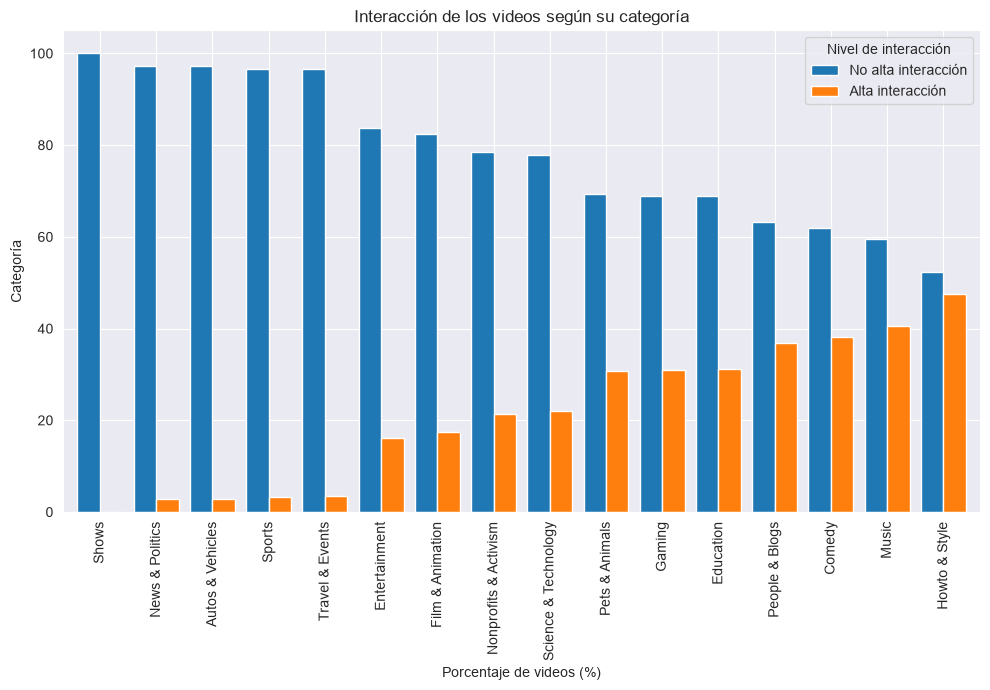

In [13]:
# Gráfico de barras comparativas
tabla.plot(kind='bar', figsize=(10, 7), width=0.8)

plt.title('Interacción de los videos según su categoría')
plt.xlabel('Porcentaje de videos (%)')
plt.ylabel('Categoría')
plt.legend(title='Nivel de interacción')
plt.tight_layout()
plt.show()

Howto & Style presenta la mayor proporción de videos con alta interacción (47,64 %), mientras que News & Politics apenas alcanza el 2,78 %. La categoría parece tener relación con el nivel de interacción.

<Figure size 600x400 with 0 Axes>

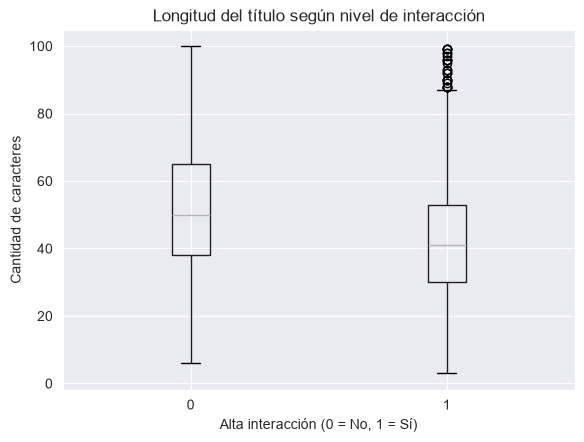

In [14]:
plt.figure(figsize=(6, 4))

df.boxplot(column='longitud_titulo', by='alta_interaccion')

plt.title('Longitud del título según nivel de interacción')
plt.suptitle('')
plt.xlabel('Alta interacción (0 = No, 1 = Sí)')
plt.ylabel('Cantidad de caracteres')
plt.show()

Los videos con alta interacción tienen títulos más cortos, con una mediana de 41 caracteres frente a 50. Sin embargo, ambos grupos presentan bastante variabilidad.

<Figure size 600x400 with 0 Axes>

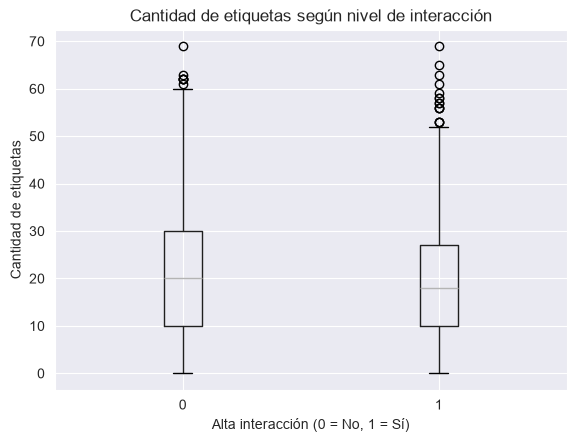

In [15]:
plt.figure(figsize=(6, 4))

df.boxplot(column='cantidad_tags', by='alta_interaccion')

plt.title('Cantidad de etiquetas según nivel de interacción')
plt.suptitle('')
plt.xlabel('Alta interacción (0 = No, 1 = Sí)')
plt.ylabel('Cantidad de etiquetas')
plt.show()

Los videos con alta interacción tienen una mediana de 18 etiquetas, frente a 20 en los demás. La diferencia es pequeña y las distribuciones son bastante similares.

### 3.3. División de los datos

In [16]:
X = df[variables]
y = df['alta_interaccion']

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Entrenamiento:', X_train.shape)
print('Prueba:', X_test.shape)

Entrenamiento: (5080, 5)
Prueba: (1271, 5)


## 4. Modelamiento

In [18]:
preprocesador = ColumnTransformer(
    transformers=[
        ('categoricas',
         OneHotEncoder(handle_unknown='ignore'),
         variables_categoricas),

        ('numericas',
         StandardScaler(),
         variables_numericas)
    ]
)

preprocesador

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categoricas', ...), ('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``

### 4.2. Construcción de los modelos

La Regresión Logística se eligió por su interpretabilidad y porque permite establecer un modelo estadístico de referencia para un problema de clasificación binaria.

In [19]:
# Regresión Logística
pipeline_logistico = Pipeline([
    ('preprocesamiento', preprocesador),
    ('modelo', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

Por su parte, Random Forest se seleccionó por su capacidad para identificar relaciones no lineales e interacciones entre las características de los videos, sin necesidad de establecer previamente una relación funcional específica.

In [20]:
# Random Forest
pipeline_forest = Pipeline([
    ('preprocesamiento', preprocesador),
    ('modelo', RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

In [21]:
# Entrenamiento de Regresión Logística
pipeline_logistico.fit(X_train, y_train)

# Entrenamiento de Random Forest
pipeline_forest.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['category_name','dia_publicacion','hora_publicacion','longitud_titulo', 'cantidad_tags']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categoricas', ...), ('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifyin

In [22]:
modelos = {
    'Regresión Logística': pipeline_logistico,
    'Random Forest': pipeline_forest
}

## 5. Evaluación

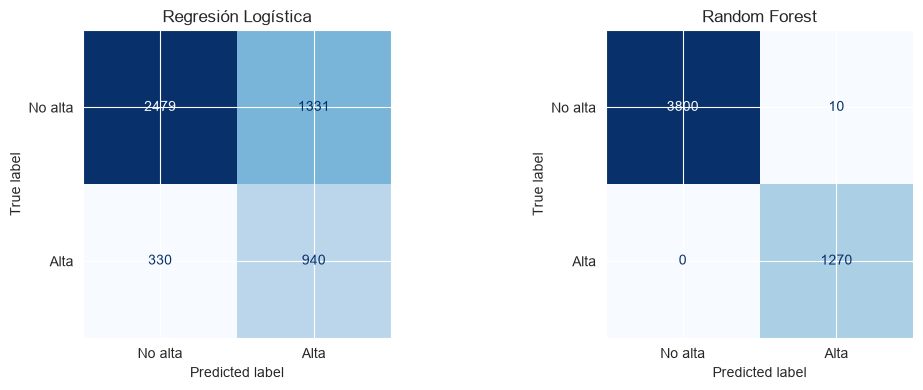

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (nombre, modelo) in zip(axes, modelos.items()):

    ConfusionMatrixDisplay.from_estimator(
        modelo,
        X_train,
        y_train,
        display_labels=['No alta', 'Alta'],
        cmap='Blues',
        values_format='d',
        ax=ax,
        colorbar=False,
    )

    ax.set_title(nombre)

plt.tight_layout()

- Regresión Logística: identifica correctamente 940 de los 1.270 videos con alta interacción, aunque clasifica erróneamente 1.331 videos como de alta interacción. Mejoró la sensibilidad, pero aumentaron los falsos positivos.
- Random Forest: identifica los 1.270 videos con alta interacción y comete solamente 10 errores. Este desempeño casi perfecto en entrenamiento sigue siendo una señal de posible sobreajuste.

In [24]:
for nombre, modelo in modelos.items():

    predicciones = modelo.predict(X_train)

    print(f'\n{nombre}')
    print('-' * 45)

    print(classification_report(
        y_train,
        predicciones,
        target_names=['No alta interacción', 'Alta interacción'],
        digits=3,
        zero_division=0
    ))


Regresión Logística
---------------------------------------------
                     precision    recall  f1-score   support

No alta interacción      0.883     0.651     0.749      3810
   Alta interacción      0.414     0.740     0.531      1270

           accuracy                          0.673      5080
          macro avg      0.648     0.695     0.640      5080
       weighted avg      0.765     0.673     0.695      5080


Random Forest
---------------------------------------------
                     precision    recall  f1-score   support

No alta interacción      1.000     0.997     0.999      3810
   Alta interacción      0.992     1.000     0.996      1270

           accuracy                          0.998      5080
          macro avg      0.996     0.999     0.997      5080
       weighted avg      0.998     0.998     0.998      5080



- Regresión Logística: alcanza un F1 de 0,531 para la clase de alta interacción. Identifica el 74 % de estos videos, aunque genera bastantes falsos positivos.
- Random Forest: obtiene un F1 de 0,996, prácticamente perfecto en entrenamiento. Sin embargo, su resultado anterior en validación (0,510) evidencia un sobreajuste considerable.

### 5.1. Curvas de aprendizaje

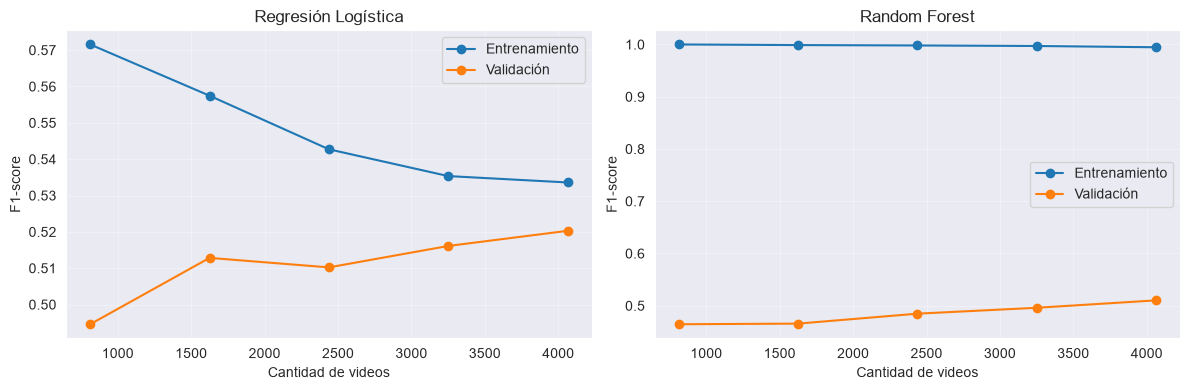

In [27]:



fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (nombre, modelo) in zip(axes, modelos.items()):

    tamaños, train_scores, val_scores = learning_curve(
        modelo, X_train, y_train,
        cv=5,
        scoring='f1',
        train_sizes=np.linspace(0.2, 1.0, 5),
        n_jobs=-1
    )

    ax.plot(tamaños, train_scores.mean(axis=1),
            marker='o', label='Entrenamiento')

    ax.plot(tamaños, val_scores.mean(axis=1),
            marker='o', label='Validación')

    ax.set_title(nombre)
    ax.set_xlabel('Cantidad de videos')
    ax.set_ylabel('F1-score')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Regresión Logística presenta un comportamiento más estable, con un F1 de validación cercano a 0,52. Random Forest muestra un sobreajuste considerable, pues alcanza casi 1,0 en entrenamiento, pero apenas 0,51 en validación.

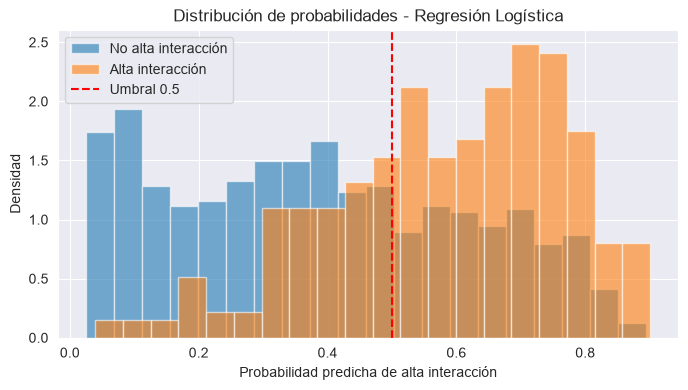

In [29]:
probabilidades = pipeline_logistico.predict_proba(X_test)[:, 1]

plt.figure(figsize=(8, 4))

plt.hist(probabilidades[y_test == 0], bins=20, alpha=0.6,
         label='No alta interacción', density=True)

plt.hist(probabilidades[y_test == 1], bins=20, alpha=0.6,
         label='Alta interacción', density=True)

plt.axvline(0.5, color='red', linestyle='--', label='Umbral 0.5')

plt.title('Distribución de probabilidades - Regresión Logística')
plt.xlabel('Probabilidad predicha de alta interacción')
plt.ylabel('Densidad')
plt.legend()
plt.show()

La Regresión Logística tiende a asignar probabilidades más altas a los videos con alta interacción y más bajas a los demás. Sin embargo, existe un solapamiento considerable entre ambos grupos, lo que dificulta su clasificación y explica parte de los errores del modelo.

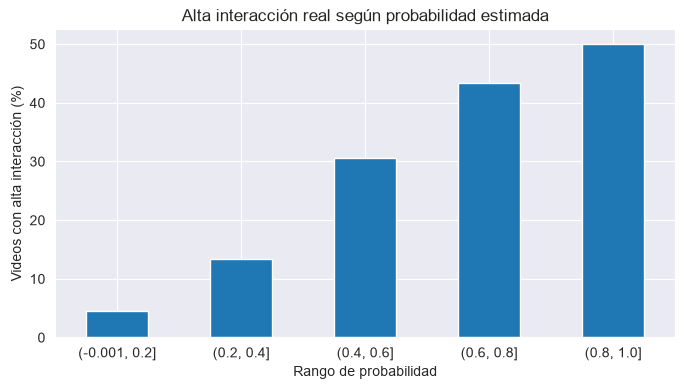

In [30]:
analisis = pd.DataFrame({
    'probabilidad': probabilidades,
    'alta_interaccion': y_test.to_numpy()
})

analisis['rango'] = pd.cut(
    analisis['probabilidad'],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1],
    include_lowest=True
)

resultado = analisis.groupby(
    'rango', observed=True
)['alta_interaccion'].mean() * 100

resultado.plot(kind='bar', figsize=(8, 4))

plt.title('Alta interacción real según probabilidad estimada')
plt.xlabel('Rango de probabilidad')
plt.ylabel('Videos con alta interacción (%)')
plt.xticks(rotation=0)
plt.show()

A mayor probabilidad estimada, mayor es la proporción de videos que realmente alcanzan alta interacción. Esto puede ayudar al negocio a priorizar contenidos con mayor potencial. Sin embargo, incluso entre los videos con puntuaciones superiores a 0,80, solo cerca del 50 % logra alta interacción, por lo que sus resultados deben utilizarse como apoyo para tomar decisiones y no como una garantía de éxito.

In [32]:

pre = pipeline_logistico.named_steps['preprocesamiento']
modelo = pipeline_logistico.named_steps['modelo']


In [33]:
# Transformar los datos
X_train_shap = pre.transform(X_train)
X_test_shap = pre.transform(X_test)

# Calcular SHAP
explainer = shap.LinearExplainer(modelo, X_train_shap)
valores_shap = explainer(X_test_shap)

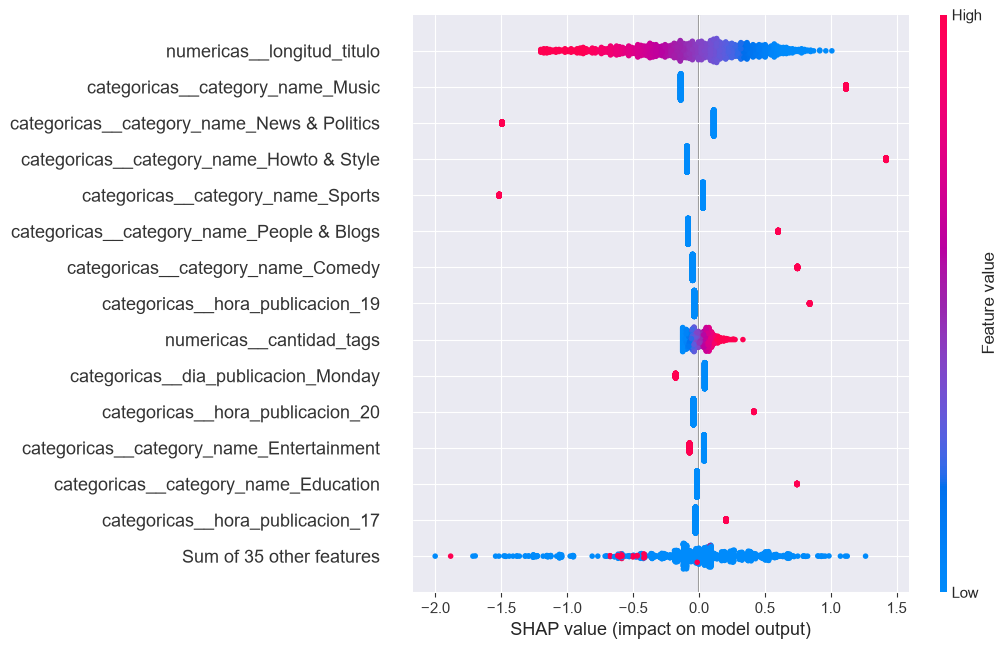

In [34]:
# Asignar nombres a las variables
valores_shap.feature_names = pre.get_feature_names_out().tolist()
# Gráfica
shap.plots.beeswarm(valores_shap, max_display=15)

- Longitud del título: es una de las variables más importantes. Los títulos cortos tienden a favorecer la predicción de alta interacción, mientras que los largos la reducen.
- Categoría del video: Music, Howto & Style y Comedy contribuyen positivamente; News & Politics y Sports presentan contribuciones negativas.
 -Cantidad de etiquetas: tiene una influencia menor. Una mayor cantidad de etiquetas tiende a aumentar ligeramente la puntuación del modelo.
- Día y hora de publicación: también aportan información, aunque su importancia es menor que la longitud del título y algunas categorías.

## 6. Conclusiones

- Categorías con mayor potencial: Howto & Style, Music y Comedy presentan buenos niveles de interacción. Son alternativas interesantes para orientar estrategias de contenido.

- Títulos más cortos: el modelo muestra que los títulos cortos se relacionan con una mayor posibilidad de alta interacción. Se recomienda probar títulos breves y claros.

- Desempeño de los modelos: Regresión Logística presentó mayor estabilidad y un F1 cercano a 0,52 en validación. Su capacidad predictiva es moderada y todavía comete errores importantes.

- Priorización de contenidos: las puntuaciones del modelo permiten ordenar videos según su potencial. Sin embargo, incluso en el grupo con puntuaciones superiores a 0,80, solo cerca del 50 % alcanzó alta interacción.

- Uso empresarial: el modelo puede apoyar la selección de ideas y campañas, pero no debe utilizarse como único criterio para decidir inversiones.

- Limitación: los resultados corresponden a videos que llegaron a tendencias en YouTube. No se puede garantizar el mismo comportamiento en todos los videos de la plataforma.

### Consideraciones eticas.
La conceptualización del proyecto, la selección de los métodos, las decisiones metodológicas y la interpretación de los resultados estuvieron bajo mi responsabilidad. Se utilizaron herramientas de inteligencia artificial como apoyo en la generación y revisión de algunos fragmentos de código. Los resultados fueron ejecutados, analizados y validados por el autor.